# Блок 7. Основы искусственного интеллекта и машинного обучения
## Занятие 10. Практика кластеризации: сегментация клиентов без внешнего CSV

## Почему переделали занятие

В прошлой версии использовался внешний CSV-файл с GitHub.  
Ссылка перестала работать и возникла ошибка `HTTP Error 404`.

В этой версии занятие сделано так, чтобы оно стабильно запускалось в Google Colab:

```python
from sklearn.datasets import make_blobs
```

Мы создаём учебный датасет клиентов прямо в ноутбуке.  
Интернет для загрузки CSV больше не нужен.

---

## Цель занятия

Научиться решать практическую задачу кластеризации:

```text
сегментация клиентов магазина
```

Мы будем искать группы клиентов по двум признакам:

| Колонка | Описание |
|---|---|
| annual_income | годовой доход клиента |
| spending_score | оценка покупательской активности от 1 до 100 |

---

## Что такое сегментация клиентов

Сегментация клиентов — это разделение клиентов на группы.

Например:

- клиенты с высоким доходом и высокими тратами;
- клиенты с высоким доходом и низкими тратами;
- клиенты со средним доходом;
- экономные клиенты;
- активные покупатели.

---

## Что такое K-Means

K-Means — алгоритм кластеризации.

Он делит объекты на группы так, чтобы похожие объекты оказались рядом.

Алгоритм:

1. Выбираем количество кластеров K.
2. Алгоритм создаёт центры кластеров.
3. Каждый клиент относится к ближайшему центру.
4. Центры пересчитываются.
5. Процесс повторяется.

---

## Зачем нужно масштабирование

K-Means основан на расстояниях.

Если один признак намного больше другого по масштабу, он будет слишком сильно влиять на результат.

Поэтому перед K-Means часто используют:

```python
StandardScaler()
```

---

## Связь с дипломом

Эту логику можно использовать в дипломных проектах:

- CRM;
- маркетинг;
- интернет-магазин;
- HR;
- фитнес;
- питание;
- недвижимость;
- финансы.

---

## GitHub

```bash
git checkout main
git pull origin main
git checkout -b feature/block7-lesson10-customer-clustering-fixed

git add .
git commit -m "fix: update customer clustering lesson without external csv"
git push -u origin feature/block7-lesson10-customer-clustering-fixed
```


Сначала изучите SOLVED-ноутбук вместе с преподавателем. Затем выполните TODO самостоятельно.

## Ячейка 1. TODO: импорт библиотек

### Алгоритм

Импортируйте pandas, numpy, matplotlib, make_blobs, StandardScaler и KMeans.

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("Библиотеки подключены")

assert pd is not None
assert np is not None
assert KMeans is not None

Библиотеки подключены


## Ячейка 2. TODO: создание учебного датасета клиентов

### Алгоритм

Создайте 300 клиентов через make_blobs и DataFrame с двумя сырыми признаками.

In [45]:
df: pd.DataFrame = pd.read_csv("../../data/daily_meal_table.csv")

print(df.shape)
display(df.head())

assert len(df) == 15322

(15322, 15)


,id,date,meal,products,energy_kcal,protein_g,fat_g,carbohydrates_g,fiber_g,sugars_g,saturated_fat_g,cholesterol_mg,sodium_mg,potassium_mg,water_g
0,0060b6899180e194092d60a0e50aeea1,2019/2/22,breakfast,2,615.0,16.39,17.35,102.97,9.4,28.38,2.796,16.0,954.0,165.0,50.60
1,0060b6899180e194092d60a0e50aeea1,2019/2/22,lunch,3,564.0,33.00,10.00,85.40,8.2,0.00,0.555,0.0,248.0,739.0,164.80
2,0060b6899180e194092d60a0e50aeea1,2019/2/22,supper,2,239.0,15.73,10.53,22.27,1.9,3.85,1.780,28.0,536.0,128.0,84.00
3,0060b6899180e194092d60a0e50aeea1,2019/2/23,breakfast,3,968.0,17.68,50.74,110.79,8.2,2.00,8.091,20.0,1600.0,563.0,115.20
4,0060b6899180e194092d60a0e50aeea1,2019/2/23,lunch,3,487.0,16.27,6.06,92.61,7.3,2.79,1.040,12.0,512.0,614.0,182.47


## Ячейка 3. TODO: приведение признаков к бизнес-смыслу

### Алгоритм

Создайте функцию масштабирования в диапазон и получите annual_income и spending_score.

In [46]:
feature_df = df[df["energy_kcal"] > 0]
kcal = feature_df["energy_kcal"]  #.replace(0, np.nan)

# feature_df: pd.DataFrame = pd.DataFrame()
feature_df["protein_share"] = (df["protein_g"] * 4 / kcal * 100).round(1)
feature_df["fat_share"] = (df["fat_g"] * 9 / kcal * 100).round(1)
feature_df["carb_share"] = (df["carbohydrates_g"] * 4 / kcal * 100).round(1)

feature_cols = ["protein_share", "fat_share", "carb_share"]
feature_df = feature_df[feature_cols]

shares = feature_df[feature_cols]
shares = shares.div(shares.sum(axis=1), axis=0) * 100
feature_df = shares


## Ячейка 4. TODO: первичное исследование датасета

### Алгоритм

Выведите русское описание колонок, статистику и пропуски.

In [47]:

column_description = {
    "protein_share": "Доля белка",
    "fat_share": "Доля жира",
    "carb_share": "Доля углеводов",
}

for column, description in column_description.items():
    print(column, "-", description)

print("Статистика")
display(feature_df.describe())

print("Пропуски")
print(feature_df.isna().sum())

assert feature_df.isna().sum().sum() == 0

protein_share - Доля белка
fat_share - Доля жира
carb_share - Доля углеводов
Статистика


,protein_share,fat_share,carb_share
count,15321.000000,15321.000000,15321.000000
mean,17.365223,36.459020,46.175757
std,13.132112,16.463627,17.105171
min,0.000000,0.000000,0.000000
25%,8.234127,24.636275,35.806133
50%,13.564356,37.931034,47.675569
75%,22.157434,45.284872,56.393130
max,95.721393,100.000000,100.000000


Пропуски
protein_share    0
fat_share        0
carb_share       0
dtype: int64


## Ячейка 5. TODO: визуализация исходных данных

### Алгоритм

Постройте scatter plot дохода и spending score без кластеров.

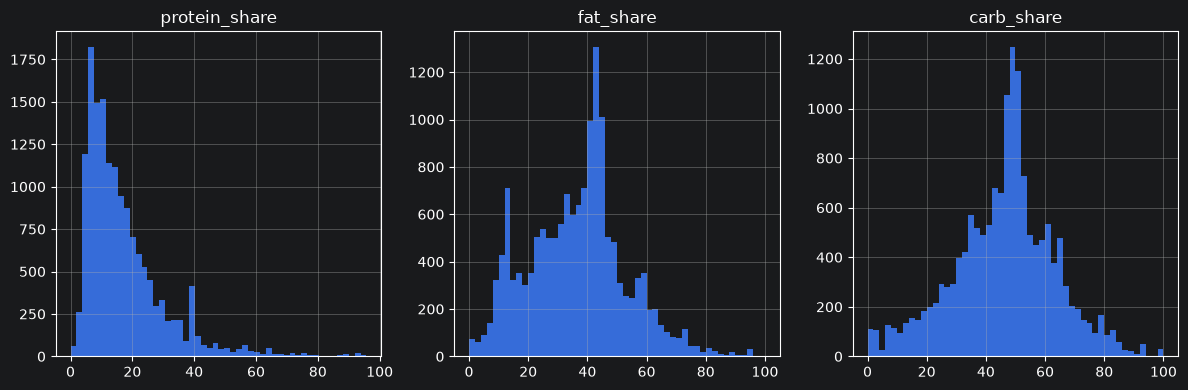

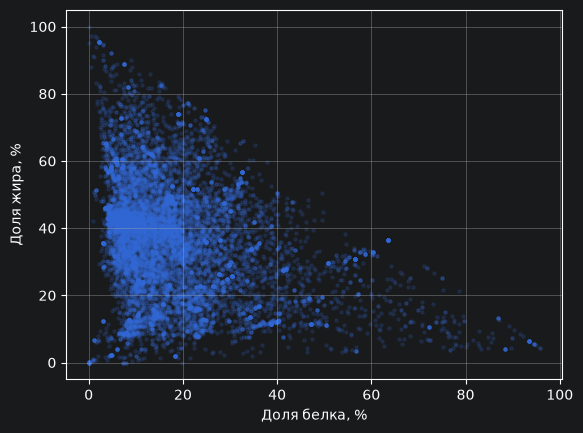

In [48]:
# 1) распределения признаков
feature_df[feature_cols].hist(bins=50, figsize=(12, 4), layout=(1, 3))
plt.tight_layout()
plt.show()

# 2) облако с прозрачностью (вместо кляксы)
plt.scatter(feature_df["protein_share"], feature_df["fat_share"], s=5, alpha=0.15)
plt.xlabel("Доля белка, %")
plt.ylabel("Доля жира, %")
plt.grid(True)
plt.show()

# 3) для композиции честнее всего — ternary plot
import plotly.express as px

px.scatter_ternary(feature_df.sample(3000), a="protein_share",
                   b="fat_share", c="carb_share")

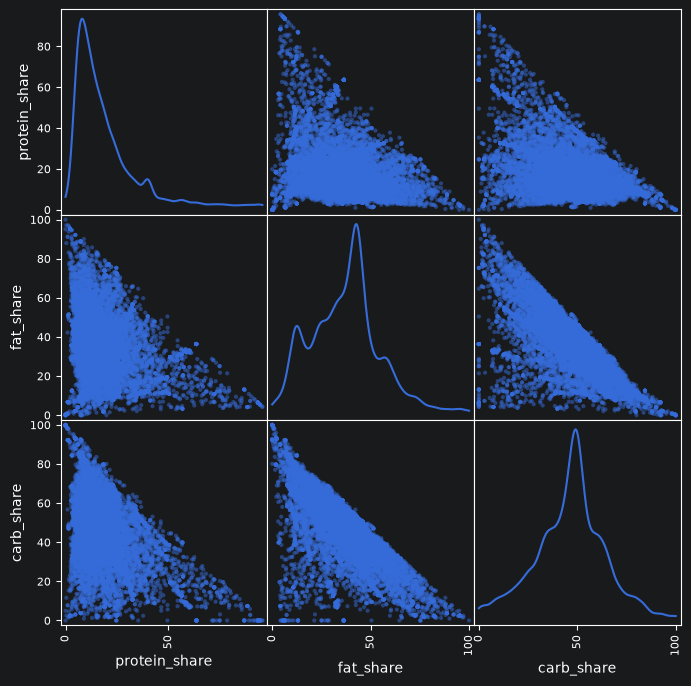

In [49]:
from pandas.plotting import scatter_matrix

scatter_matrix(feature_df[feature_cols], figsize=(8, 8), diagonal="kde")
plt.show()

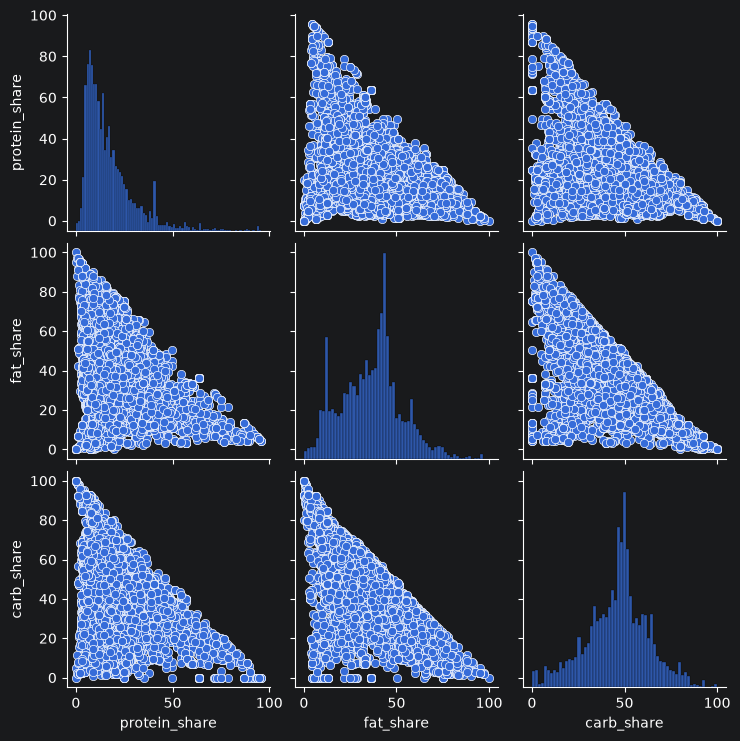

In [50]:
import seaborn as sns

sns.pairplot(feature_df[feature_cols])
plt.show()


## Ячейка 6. TODO: масштабирование признаков

### Алгоритм

Выберите признаки, создайте StandardScaler и получите X_scaled.

In [51]:
# TODO: создайте features
features = ["protein_share", "fat_share"]
# TODO: создайте X
X = feature_df[features]
# TODO: создайте scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# TODO: создайте X_scaled
print("Size", X.shape)
print("Size scaled", X_scaled.shape)
# TODO: assert X_scaled.shape == X.shape

assert X_scaled.shape == X.shape

Size (15321, 2)
Size scaled (15321, 2)


## Ячейка 7. TODO: метод локтя

### Алгоритм

Для K от 1 до 10 обучите KMeans, сохраните inertia и постройте график.

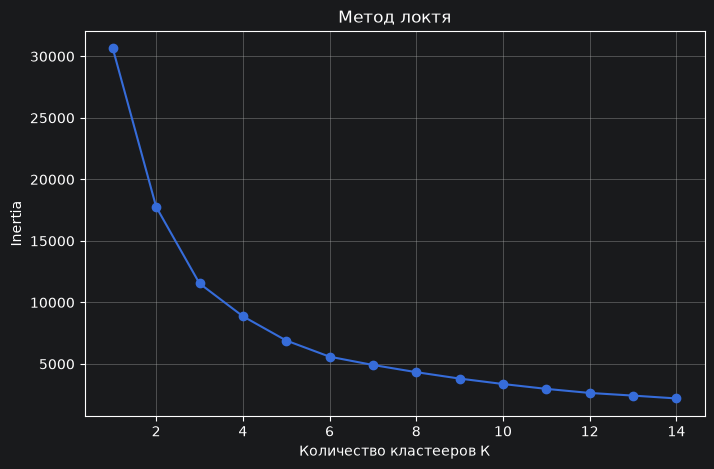

In [52]:
# TODO: создайте inertia
inertia = []
# TODO: создайте k_values
k_values = range(1,15)
# TODO: в цикле обучите KMeans для разных K
for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)
# TODO: постройте график метода локтя

plt.figure(figsize=(8,5))
plt.plot(list(k_values), inertia, marker="o")
plt.title("Метод локтя")
plt.xlabel("Количество кластееров К")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

assert len(inertia) == len(k_values)

## Ячейка 8. TODO: обучение K-Means

### Алгоритм

Обучите KMeans с n_clusters=5 и добавьте колонку cluster.

In [53]:
# TODO: создайте kmeans
kmeans = KMeans(
    n_clusters = 4,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)
# TODO: обучите kmeans
feature_df["cluster"] = kmeans.labels_
# TODO: добавьте df["cluster"]

# TODO: выведите value_counts()
print("Количество клиентов в каждом кластере:")
print(feature_df["cluster"].value_counts().sort_index())

assert feature_df["cluster"].nunique() == 4


Количество клиентов в каждом кластере:
cluster
0    2480
1    3892
2    7163
3    1786
Name: count, dtype: int64


## Ячейка 9. TODO: визуализация кластеров

### Алгоритм

Постройте scatter plot с цветами по кластерам.

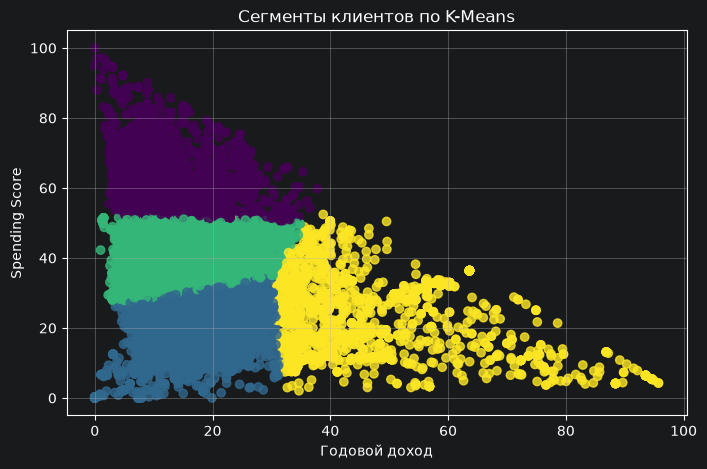

In [54]:
plt.figure(figsize=(8, 5))

plt.scatter(
    feature_df["protein_share"],
    feature_df["fat_share"],
    c=feature_df["cluster"],
    alpha=0.8
)

plt.title("Сегменты клиентов по K-Means")
plt.xlabel("Годовой доход")
plt.ylabel("Spending Score")
plt.grid(True)
plt.show()

assert "cluster" in feature_df.columns

## Ячейка 10. TODO: интерпретация кластеров и отчёт

### Алгоритм

Сгруппируйте данные по cluster, создайте final_report и список conclusions.

In [56]:
# Ячейка 10. Интерпретация кластеров и отчёт

# TODO: cluster_report
cluster_report = (
    feature_df.groupby("cluster")
    .agg(
        meals_count=("protein_share", "size"),
        avg_protein=("protein_share", "mean"),
        avg_fat=("fat_share", "mean"),
        avg_carb=("carb_share", "mean"),
    )
    .round(1)
    .sort_values(by="avg_protein", ascending=False)
)

display(cluster_report)

# условно "лучший" = самый высокобелковый приём, "низкий" = самый низкобелковый
best_cluster = cluster_report["avg_protein"].idxmax()
low_cluster = cluster_report["avg_protein"].idxmin()

# TODO: final_report
final_report = {
    "rows": len(feature_df),
    "clusters": int(feature_df["cluster"].nunique()),
    "best_cluster": int(best_cluster),
    "low_cluster": int(low_cluster),
    "best_avg_protein": float(cluster_report.loc[best_cluster, "avg_protein"]),
    "low_avg_protein": float(cluster_report.loc[low_cluster, "avg_protein"]),
}

print("Итоговый отчёт:")
for key, value in final_report.items():
    print(f"  {key}: {value}")

# TODO: conclusions
conclusions = [
    "Кластеризация без учителя разбила приёмы пищи на группы по макропрофилю.",
    f"K-Means нашёл {final_report['clusters']} сегмента питания (K={kmeans.n_clusters}).",
    f"Самый высокобелковый сегмент — кластер {best_cluster} ({final_report['best_avg_protein']:.1f}% белка).",
    f"Самый низкобелковый сегмент — кластер {low_cluster} ({final_report['low_avg_protein']:.1f}% белка).",
    "Доли БЖУ композиционны (сумма ≈ 100%), поэтому для K-Means достаточно двух признаков.",
]

print()
print("Выводы:")
for item in conclusions:
    print("-", item)

# TODO: assert
assert cluster_report.shape[0] == kmeans.n_clusters
assert final_report["clusters"] == kmeans.n_clusters
assert len(conclusions) == 5

,meals_count,avg_protein,avg_fat,avg_carb
cluster,,,,
3,1786,45.6,21.4,33.0
1,3892,16.4,19.2,64.3
0,2480,12.9,62.0,25.1
2,7163,12.4,40.7,46.9


Итоговый отчёт:
  rows: 15321
  clusters: 4
  best_cluster: 3
  low_cluster: 2
  best_avg_protein: 45.6
  low_avg_protein: 12.4

Выводы:
- Кластеризация без учителя разбила приёмы пищи на группы по макропрофилю.
- K-Means нашёл 4 сегмента питания (K=4).
- Самый высокобелковый сегмент — кластер 3 (45.6% белка).
- Самый низкобелковый сегмент — кластер 2 (12.4% белка).
- Доли БЖУ композиционны (сумма ≈ 100%), поэтому для K-Means достаточно двух признаков.


# Итог TODO-задания

Покажите преподавателю:

- стабильный датасет без внешней ссылки;
- метод локтя;
- обученный K-Means;
- визуализацию кластеров;
- интерпретацию сегментов;
- бизнес-отчёт.